In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [3]:
data = pd.read_csv('p2 data .csv')
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
#del data['unnamed: 32']

In [9]:
x= data.iloc[:,2:].values
y= data.iloc[:,1] .values

#encoding categorical data
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
y=le.fit_transform(y)

#splitting the dataset 
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.1, random_state = 0)

#feature scaling:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)   # fit not exist ?  -->


In [11]:
x_train.shape

(512, 30)

In [12]:
#Now that we have prepared data, we will import Keras and its packages.

In [14]:
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout

In [17]:
model = Sequential()

#input layer and 1st hidden layer
model.add(Dense(units =16, kernel_initializer ="uniform", activation='relu', input_dim =30))
#addiing dropout to prevent overfitting
model.add(Dropout(rate=0.1))

#2st hidden layer
model.add(Dense(units =16, kernel_initializer ="uniform", activation='relu', input_dim =30))
model.add(Dropout(rate = 0.1))

model.add(Dense(units =16, kernel_initializer ="uniform", activation='relu', input_dim =30))
model.add(Dropout(rate = 0.1))

model.add(Dense(units = 1, kernel_initializer = 'uniform', activation = 'sigmoid')) 

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,057 (4.13 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.compile(optimizer= 'adam', loss='binary_crossentropy' , metrics=['accuracy'])

In [20]:
# Fitting the ANN to the Training set
history = model.fit(x_train,y_train, validation_split=0.2, batch_size=64, epochs=2)

Epoch 1/2
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.5230 - loss: 0.6929 - val_accuracy: 0.6019 - val_loss: 0.6923
Epoch 2/2
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6423 - loss: 0.6917 - val_accuracy: 0.6019 - val_loss: 0.6912


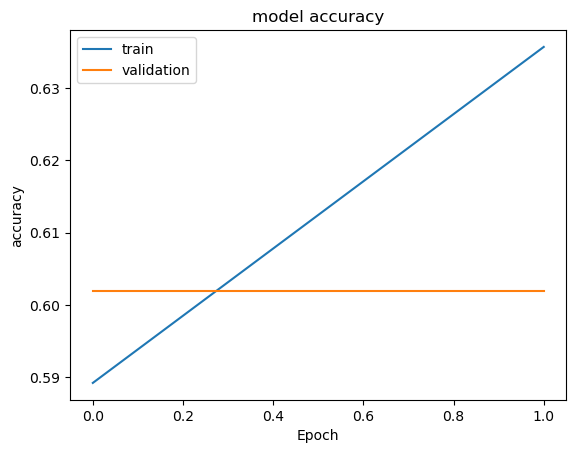

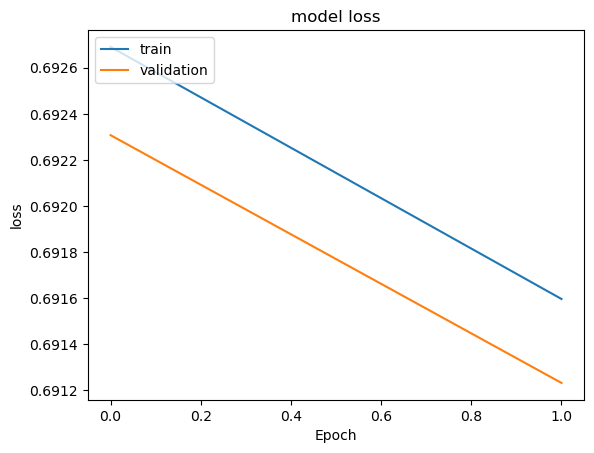

In [22]:
import matplotlib.pyplot as plt

#plot trainig and validation accuracy values
plt.plot(history.history['accuracy']) ## Access history from the 'history' object
plt.plot(history.history['val_accuracy'])

plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

#plot trainig and validation loss values
plt.plot(history.history['loss']) ## Access history from the 'history' object
plt.plot(history.history['val_loss'])

plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()


In [25]:
# Predicting the Test set results
y_pred = model.predict(x_test)
y_pred = (y_pred >=0.5)   #???

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


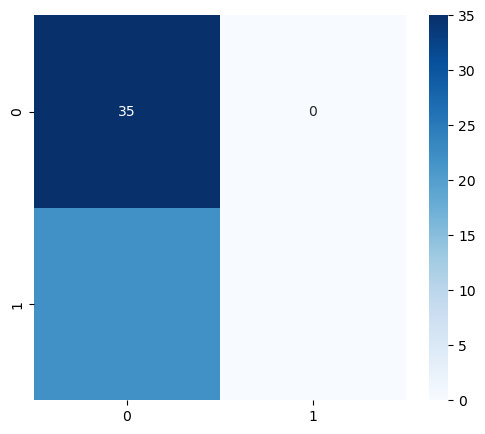

In [27]:
## Confusion matrix with blue colors wiyh 6*5 fig size

from sklearn.metrics import confusion_matrix

cm=confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, cmap='Blues', annot=True, fmt="g")
plt.show()

In [28]:
from sklearn.metrics import classification_report

CR=classification_report(y_test, y_pred, digits=4)

print(CR)

              precision    recall  f1-score   support

           0     0.6140    1.0000    0.7609        35
           1     0.0000    0.0000    0.0000        22

    accuracy                         0.6140        57
   macro avg     0.3070    0.5000    0.3804        57
weighted avg     0.3770    0.6140    0.4672        57



C:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
